In [47]:
import matplotlib.pyplot as plt
import numpy as np

## Data settings

In [48]:
final_times = [4.5, 4.5, 4.5]
h_dts = [0.125, 0.125, 0.15]
tn_dts = [0.01, 0.01, 0.01]

plot_times = [4, 4, 4]
h_data_limits = [int(np.ceil(pt / hdt))+1 for pt, hdt in zip(plot_times, h_dts)]
tn_data_steps = [int(hdt / tndt) for hdt, tndt in zip(h_dts, tn_dts)]
tn_data_limits = [int(np.ceil(ft / tndt))+1 for ft, tndt in zip(plot_times, tn_dts)]

## Load data

In [49]:
from utils.postselection_multithreaded import load_job_result
import load_data as load
import numpy as np
import pickle

hdatas, tndatas = load.load_single_string_data()

hobs = []
hconfs = []
tnobs = []

for hdata, tndata in zip(hdatas, tndatas):
    hobs.append(hdata[0][0])
    hconfs.append(hdata[1][0])
    tnobs.append(tndata)

s = hdatas[2][2][0][0][0]

confusion_matrices = np.load("../data/confusion_matrices.npy")

Loading col1 data
Loading col2 data
Loading col3 data


In [50]:
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.postselection_multithreaded import initialize_postselection, get_postselected_samples_dict, get_recovered_postselected_samples_dict
from z2hex.geometry import HeavyHexLattice
 
plaquette_width = 3
plaquette_height = 3

lattice = HeavyHexLattice(plaquette_width, plaquette_height)

observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)
postselection_operators_func2 = lambda nqubits: [local_pauli_z(lattice, i) for i in lattice.node_qbinds]

pops, dobs, ndobs, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)
pops2, dobs2, ndobs2, basis2 = initialize_postselection(len(lattice), postselection_operators_func2, observable_generating_funcs)

In [51]:
def mitigate_single_bitstring(z_rinv_all: list[np.ndarray], bitstring: np.ndarray) -> float:
    """Return the mitigated Pauli expectation value for a single observed bitstring.

    Args:
        z_rinv_all: A list of single-qubit pauli-Z (as a vector) contracted with the single-qubit
            inverse response matrix, for each qubit.
        bitstring: The measured bitstring.

    Returns:
        The corrected expectation value of ZZZZZ... given the single measured bitstring.
    """
    return np.prod([z_rinv[bit] for z_rinv, bit in zip(z_rinv_all, bitstring)])

In [52]:
def mitigate_single_bitstring(z_rinv_all: list[np.ndarray], bitstring: np.ndarray) -> float:
    """Return the mitigated Pauli expectation value for a single observed bitstring.

    Args:
        z_rinv_all: A list of single-qubit pauli-Z (as a vector) contracted with the single-qubit
            inverse response matrix, for each qubit.
        bitstring: The measured bitstring.

    Returns:
        The corrected expectation value of ZZZZZ... given the single measured bitstring.
    """
    return np.prod([z_rinv[bit] for z_rinv, bit in zip(z_rinv_all, bitstring)])

In [53]:
layout = np.array([87, 86, 85, 77, 65, 64, 63, 56, 43, 42, 41, 36, 21, 88, 66, 44, 22, 91, 90, 89, 78, 69, 68, 67, 57, 47, 46, 45, 37, 25, 24, 23, 92, 70, 48, 26, 93, 79, 73, 72, 71, 58, 51, 50, 49, 38, 29, 28, 27, 17, 7, 74, 52, 30, 8, 75, 59, 55, 54, 53, 39, 33, 32, 31, 18, 11, 10, 9])

mm_obs = []
for i in range(len(lattice)):
    qubits = [i]

    inv_conf_mats = np.array([np.linalg.inv(cm) for cm in confusion_matrices[layout[qubits]]])
    inv_conf_mats_timesz = [np.array([1, -1]) @ inv_cm for inv_cm in inv_conf_mats]
    # inv_conf_mats_timesz

    measured_bitstrings = np.zeros((sum(s.values()), len(qubits)), dtype=int)
    i = 0
    for bitstring, count in s.items():
        bitstring_array = np.array([int(b) for b in bitstring])
        measured_bitstrings[i:i+count, :] = bitstring_array[qubits][::-1]
        i += count

    z_mit_all_shots = np.array(
        [
            mitigate_single_bitstring(inv_conf_mats_timesz, bitstring)
            for bitstring in measured_bitstrings
        ]
    )
    mm_obs.append(np.mean(z_mit_all_shots))

In [54]:
conf = np.ones(len(lattice), dtype=int)
string = [4, 14, 24, 34, 45, 53, 63]
conf[string] = -1

In [55]:
conf

array([ 1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,
        1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,
        1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1])

In [56]:
expected_observables = np.round(hdata[0][1][0][:len(lattice)])
expected_observables

array([ 1.,  1.,  1.,  1., -1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1., -1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1., -1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,
        1.,  1.,  1.])

In [57]:
qubits = [string[2]]
layout = np.array([109, 110, 111, 98, 91, 92, 93, 79, 73, 74, 75, 59, 55, 108, 90, 72, 54, 105, 106, 107, 97, 87, 88, 89, 78, 69, 70, 71, 58, 51, 52, 53, 104, 86, 68, 50, 103, 96, 83, 84, 85, 77, 65, 66, 67, 57, 47, 48, 49, 38, 29, 82, 64, 46, 28, 81, 76, 61, 62, 63, 56, 43, 44, 45, 37, 25, 26, 27])

inv_conf_mats = np.array([np.linalg.inv(cm) for cm in confusion_matrices[layout[qubits]]])
inv_conf_mats_timesz = [np.array([1, -1]) @ inv_cm for inv_cm in inv_conf_mats]
# inv_conf_mats_timesz

measured_bitstrings = np.zeros((sum(s.values()), len(qubits)), dtype=int)
i = 0
for bitstring, count in s.items():
    bitstring_array = np.array([int(b) for b in bitstring])
    measured_bitstrings[i:i+count, :] = bitstring_array[qubits][::-1]
    i += count

z_mit_all_shots = np.array(
    [
        mitigate_single_bitstring(inv_conf_mats_timesz, bitstring)
        for bitstring in measured_bitstrings
    ]
)

np.mean(z_mit_all_shots)

np.float64(1.0590677214679867)

In [58]:
conf

array([ 1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,
        1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,
        1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1])

In [59]:
np.round(mm_obs, decimals=1)[string]

array([-1. , -1. ,  1. ,  1. ,  1. , -1. , -1.1])

In [60]:
expected_observables = np.round(hdata[0][1][0][:len(lattice)])
expected_observables

array([ 1.,  1.,  1.,  1., -1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1., -1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1., -1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,
        1.,  1.,  1.])

In [61]:
np.abs(mm_obs-expected_observables)

array([8.19653867e-03, 1.61359764e-02, 1.47145647e-03, 7.60922074e-03,
       2.32741083e-02, 4.36524466e-02, 6.31255461e-03, 8.50005858e-03,
       3.45014728e-03, 4.09081808e-03, 7.48116848e-04, 4.76110682e-02,
       9.28849572e-03, 1.60419322e-01, 1.12339300e-02, 1.17988670e-02,
       4.77827345e-02, 1.16022859e-03, 6.38369361e-03, 5.33211874e-03,
       6.64418309e-02, 2.90810765e-03, 2.00508523e+00, 7.13833242e-03,
       1.98241161e+00, 2.14367104e-03, 1.24652888e-02, 8.21805482e-03,
       1.48557832e-02, 3.54345163e-03, 2.80960953e-02, 7.16474129e-04,
       2.93940246e-02, 2.04271614e+00, 1.98541481e+00, 3.04237792e-03,
       6.83410324e-03, 4.68400886e-03, 1.60346763e-01, 7.69546732e-03,
       2.12791213e-03, 2.95888589e-02, 1.10873217e-01, 2.00126228e+00,
       3.71337670e-02, 1.99141685e+00, 2.76595508e-03, 1.06692223e-02,
       2.04088381e-02, 6.92707900e-03, 6.08312406e-02, 1.69095890e-04,
       5.75294504e-02, 1.05664749e-02, 1.25785585e-02, 1.08159571e-02,
      

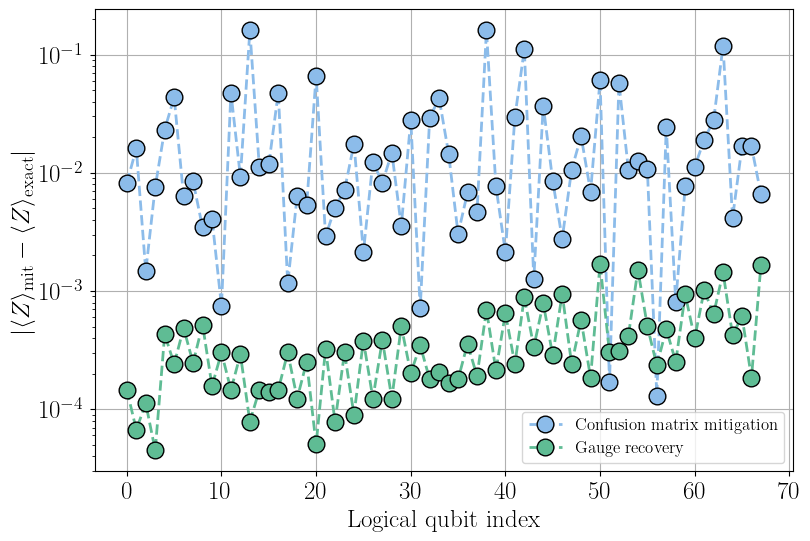

In [ ]:
import matplotlib.pyplot as plt

plt.rc("text", usetex=True)
plt.rc("font", size=18, family="serif", weight="bold")

fig, ax = plt.subplots(figsize=[9, 6])

colors = ["#8CBCEA", "#5FBC94", "#e2d439", "#EC874C", "#EF8082", "#E094D7", "#D7AC63", "#AC9CF4", "#959C9E"]

plt.plot(np.arange(len(lattice)), np.abs(mm_obs-expected_observables[::-1]), "o--", markersize=12, linewidth=2, markeredgecolor="black", color=colors[0], label="Confusion matrix mitigation")
plt.plot(np.arange(len(lattice)), np.abs(hdata[0][1][0][:len(lattice)]-expected_observables), "o--", markersize=12, linewidth=2, markeredgecolor="black", color=colors[1], label="Gauge recovery")
plt.xlabel("Logical qubit index")
plt.ylabel(r"$\left| \langle Z \rangle_{\mathrm{mit}} - \langle Z \rangle_{\mathrm{exact}} \right|$")
plt.yscale("log")
plt.legend(fontsize=12)
plt.grid()
plt.savefig("/results/measure_mitigation_vs_gauge_recovery.pdf")